<a href="https://colab.research.google.com/github/Kannan2207/Hexavlsi-labs/blob/main/netflix_review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import kagglehub

# 1. Download/fetch the dataset path automatically
path = kagglehub.dataset_download(
    "samartalwar/netflix-360-daily-stock-app-sentiment-and-releases"
)

print("Path to dataset files:", path)

# 2. Load it straight into a Pandas DataFrame
# (Replace 'netflix_360.csv' with the actual file name inside your downloaded folder)
import os

file_name = os.listdir(path)[0]  # Gets the first file automatically
df = pd.read_csv(os.path.join(path, file_name))

# 3. View the first few rows
df.head()

100%|██████████| 47.2k/47.2k [00:00<00:00, 44.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/samartalwar/netflix-360-daily-stock-app-sentiment-and-releases/versions/27


,# netflix-daily-dataset-updater


In [2]:
import os
import pandas as pd

# 'path' is the variable where kagglehub stored your files
print("Files in dataset folder:", os.listdir(path))

# Automatically find and read the primary CSV file
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]

if csv_files:
  file_path = os.path.join(path, csv_files[0])
  df = pd.read_csv(file_path)
  print(f"\nSuccessfully loaded '{csv_files[0]}'!")
  display(df.head())
else:
  print("No CSV file found directly. Checking subfolders...")

Files in dataset folder: ['README.md', 'netflix_daily_master.csv', 'updater.py']

Successfully loaded 'netflix_daily_master.csv'!


,date,stock_close,stock_volume,stock_daily_return_pct,reviews_count,reviews_avg_rating,reviews_sentiment_score,titles_released_count,titles_avg_imdb_score,is_trading_day
0,2018-09-12,36.99,104808000,3.027,28,3.18,0.1950,2,7.60,1
1,2018-09-13,36.81,83661000,-1.011,37,2.81,0.2291,2,7.30,1
2,2018-09-14,36.46,47564000,-1.083,34,3.06,0.2325,11,6.78,1
3,2018-09-15,36.46,0,0.000,44,2.91,-0.0454,16,6.86,0
4,2018-09-16,36.46,0,0.000,46,3.33,0.3359,2,6.90,0


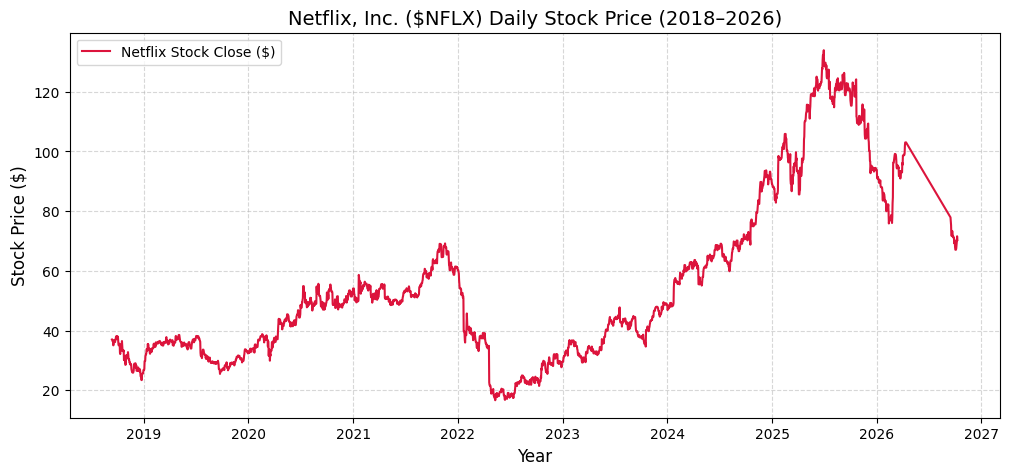

In [3]:
import matplotlib.pyplot as plt

# 1. Convert the 'date' column to actual datetime objects so Python understands the timeline
df['date'] = pd.to_datetime(df['date'])

# 2. Set the date as the index for clean time-series plotting
df_plot = df.set_index('date')

# 3. Create a clean line chart for Netflix's stock close price
plt.figure(figsize=(12, 5))
plt.plot(
    df_plot.index,
    df_plot['stock_close'],
    color='crimson',
    linewidth=1.5,
    label='Netflix Stock Close ($)',
)

plt.title('Netflix, Inc. ($NFLX) Daily Stock Price (2018–2026)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Stock Price ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# 1. Create a target: Did the stock go up the next day? (1 = Yes, 0 = No)
df['target'] = (df['stock_close'].shift(-1) > df['stock_close']).astype(int)

# Drop the last row because shift(-1) creates a missing value at the very end
df_ml = df.dropna().copy()

# 2. Select our engineered features (Sentiment, Reviews, Content drops, Volume)
features = [
    'reviews_avg_rating',
    'reviews_sentiment_score',
    'titles_released_count',
    'titles_avg_imdb_score',
    'stock_volume',
    'stock_daily_return_pct',
]

X = df_ml[features]
y = df_ml['target']

# 3. Split into training and testing data (chronologically, without shuffling)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

# 4. Train a Machine Learning model (Random Forest)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Test the model and print the accuracy score
preds = model.predict(X_test)
print(f'Model Accuracy: {accuracy_score(y_test, preds) * 100:.2f}%')

Model Accuracy: 64.19%


In [5]:
import pandas as pd

# Extract feature importances from your trained Random Forest model
feature_imp_df = pd.DataFrame(
    {'Feature': features, 'Importance': model.feature_importances_}
).sort_values(by='Importance', ascending=False)

print('--- What Drives the Model? ---')
print(feature_imp_df.to_string(index=False))

--- What Drives the Model? ---
                Feature  Importance
reviews_sentiment_score    0.201052
  titles_avg_imdb_score    0.185365
     reviews_avg_rating    0.178067
           stock_volume    0.153415
 stock_daily_return_pct    0.151031
  titles_released_count    0.131070
